# Autoencoder latent spaces on the Nature 2024 data

The awareness layer's first stage is an autoencoder whose latent space a novelty score (LOF) later reads. This notebook
trains nothing; it looks at latent spaces trained on the cluster (`ml/nature/awareness/`) and asks, visually, how
well they separate the 26 Nature tasks and the groupings that matter for control:

| model | regularization | idea |
|---|---|---|
| **vanilla AE** | none | the ankle paper's autoencoder: simple, a baseline, may spend capacity on noise |
| **sparse AE (L1)** | L1 on the latent, scale-free | like LASSO next to linear regression: each latent unit is pushed to stay at zero for most windows, so units should specialize |

Each is trained on two input settings: the ankle paper's **1 s of the 16 raw channels** (sections 1 to 3), and the
setting the feature notebooks found best, **3 s of raw channels plus the spectral features** (section 4, *Engineered
features*). All are trained only on **in-distribution** windows (the cyclic ID-safe tasks) of 14 training participants,
as in the ankle paper. Everything shown comes from **4 test participants** the models never saw, across **all 26
tasks**, and every model is drawn on the same windows.

No cluster or separation scores are computed yet; this is a visual first look. Three *views* place the windows in 2-D
and 3-D (the latent units themselves, PCA, UMAP), and five *lenses* colour them (task, task family, controller class,
up / down direction, and the Science Robotics mode a task shares).

## Findings at a glance

- **All twelve models trained cleanly** (two variants, two input settings, three seeds). On 1 s raw inputs the vanilla
  AE reaches a validation MSE of 0.247 ± 0.005 and the sparse AE 0.313 ± 0.007 at a scale-free L1 of 0.25 (vanilla
  0.90). On 3 s raw + spectral inputs: 0.269 ± 0.002 and 0.306 ± 0.014 at L1 0.10 (vanilla 0.84). Errors compare only
  within a setting.
- **The engineered inputs change the geometry more than the sparsity penalty does.** On 1 s windows both models lay gait
  out as rings traced by the gait cycle, shared by walking, ramps and curbs. On 3 s + spectral inputs those rings
  collapse into one walking cluster, and jump / run / cut, the squat / lift / sit tasks and the standing tasks move to
  their own regions.
- **Only the sparse model on engineered inputs builds novelty units.** 18 ± 7 of its roughly 27 active latent units
  respond at least five times more strongly to some task it never saw than to any walking or stairs window: mostly
  running and jumping, then sit-to-stand, cutting, step-ups, lifting and squats. The 1 s sparse model has
  2 ± 1 such units and the vanilla models at most one. In its UMAP the training tasks form one compact cluster and the
  OOD-dangerous tasks lie mostly along a separate arc.
- **On 1 s inputs the sparse code does not carry over to new people.** Its training sparsity keeps improving while the
  validation participants' sparsity worsens after about epoch 10 (by epoch 15: 0.15 on training people, 0.53 on new
  ones), so early stopping keeps a fairly dense model. On 3 s + spectral inputs the sparsity holds (about 0.10 on both).
- **Direction appears with longer context.** On 1 s inputs only stair descent separates. On 3 s + spectral inputs stair
  ascent and descent separate in both models and ramp ascent and descent take opposite sides of the walking cluster;
  curbs still mix.
- **Controller classes are still not clusters**, but on 3 s + spectral inputs ID-safe walking concentrates in one
  region and the OOD-dangerous tasks mostly sit away from it, most clearly in the sparse model.
- **Lowering the sparsity penalty does not fix the collinear latent.** The λ 0.3 model's strongest units fire as one
  block (|r| 1.00 between the top two in every seed). λ 0.1 makes the latent more redundant (3.1 against 4.5
  effective directions) and loses most novelty units; reshaping the latent to 8 filters x 4 steps ties (4.7) at a
  higher reconstruction cost. The duplication comes from units firing together, which a per-unit penalty cannot see
  (section 5).

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):   # shared code, Nature data, plot helpers
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _latent_views as lv

RUNS = REPO / 'notebooks' / 'nature' / 'model_exploration' / 'runs' / 'ae'   # pulled by ml/nature/awareness/slurm/pull.sh
DATA = REPO / 'data' / 'processed_nature' / 'ae'                              # built by ml/nature/awareness/ae_data.py
VIEW_CACHE = REPO / 'data' / 'cache' / 'nature' / 'ae_views'
MODELS = {'vanilla AE': ('vanilla', 'raw_1s'), 'sparse AE (L1)': ('sparse', 'raw_1s'),               # name: (run stem, inputs)
          'vanilla AE · 3 s + spectral': ('vanilla_raw_3s_spectral', 'raw_3s_spectral'),
          'sparse AE (L1) · 3 s + spectral': ('sparse_raw_3s_spectral', 'raw_3s_spectral'),
          'sparse AE (L1) · 3 s + spectral · λ 0.1': ('sparse_raw_3s_spectral_l0.1', 'raw_3s_spectral'),
          'vanilla AE · 3 s + spectral · 8x4 latent': ('vanilla_raw_3s_spectral_8x4', 'raw_3s_spectral'),
          'sparse AE (L1) · 3 s + spectral · λ 0.1 · 8x4 latent': ('sparse_raw_3s_spectral_l0.1_8x4', 'raw_3s_spectral')}
RAW_1S, ENGINEERED, REVISED = list(MODELS)[:2], list(MODELS)[2:4], list(MODELS)[4:]
SEEDS = (0, 1, 2)
SHOWN_SEED = 0
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
runs = {(name, seed): lv.load_run(RUNS / f'{stem}_s{seed}', tables[i]) for name, (stem, i) in MODELS.items() for seed in SEEDS}
print(f'{len(runs)} runs; code: {sorted({r["summary"]["git_sha"] for r in runs.values()})}')
print('participants:', {k: ', '.join(v) for k, v in meta['split'].items()})

21 runs; code: ['4acacfc-dirty']
participants: {'train': 'BT01, BT02, BT03, BT06, BT08, BT10, BT11, BT14, BT16, BT17, BT18, BT20, BT23, BT24', 'val': 'BT09, BT12, BT13, BT21', 'test': 'BT07, BT15, BT19, BT22'}


## 1. What was trained

| | |
|---|---|
| inputs | the existing pipeline's 16 channels: per thigh, IMU accelerometer and gyro (axes remapped to the Science Robotics order) plus hip encoder angle and velocity (recomputed causally, as Nature's is half scale) |
| windows | 1 s (200 samples) every 50 ms, standardized per channel on training windows |
| model | `ml/common/models/autoencoder.py`, the ankle paper's conv autoencoder: 16 x 200 -> 4 filters x 8 steps = 32 latent values (non-negative, ReLU) |
| training set | in-task windows of the ID-safe tasks (normal, incline and weighted walking, stairs) of 14 participants: 119,682 windows |
| early stopping | patience 5 on 4 validation participants (38,054 ID-safe windows); Adam, learning rate 0.003, batch 1,024 |
| seeds | 3 per model, one GPU each |
| validation | BatchNorm statistics recomputed on 50 training batches before each validation; for the sparse model λ ramps up over the first 5 epochs (both explained in section 4) |

**The sparse penalty.** The loss adds λ x the mean, over windows and latent units, of z / RMS(z), with the RMS taken
per unit over the batch. A plain L1 term (mean of z) does not work in this model: the decoder's first layer is followed
by BatchNorm, which makes reconstruction blind to the latent's scale, so the network can shrink every unit and pay
almost no penalty without becoming sparse. Measured on a 30,000-window training subset:

| run (40 epochs, subset) | validation MSE | scale-free L1 | values > 0 | mean latent value |
|---|---|---|---|---|
| vanilla | 0.261 | 0.88 | 100% | 0.92 |
| plain L1, λ 0.1 | 0.297 | 0.68 | 73% | 0.04 |
| scale-free L1, λ 0.1 | 0.300 | 0.36 | 74% | 0.26 |
| **scale-free L1, λ 0.3 (used)** | 0.335 | 0.19 | 55% | 0.10 |
| scale-free L1, λ 1.0 | 0.420 | 0.11 | 17% | 0.03 |

Plain L1 shrank the latent twenty-fold while staying nearly as dense as vanilla; the scale-free version makes units
genuinely quiet. λ 0.3 is the strongest weight that keeps reconstruction within about 30% of vanilla. A scale-free L1
of 1 means every unit is equally active in every window; sqrt(p) means each unit fires in a fraction p of windows.

For scale: a copy of each window keeping only its content below 4 Hz (the rate the latent's 8 steps per second can
represent) would score an MSE of 0.22. That is a reference, not a floor: the decoder's convolutions can add finer detail.

Mean ± SD over three seeds (validation participants, ID-safe windows)


,val MSE,val scale-free L1,values > 0,dead units (of 32),best epoch
model,,,,,
vanilla AE,0.247 ± 0.005,0.902 ± 0.020,0.988 ± 0.019,0.0 ± 0.0,38 ± 6
sparse AE (L1),0.313 ± 0.007,0.249 ± 0.022,0.756 ± 0.069,0.3 ± 0.6,9 ± 1


best epoch  epochs run  val MSE  val scale-free L1  values > 0  dead units (of 32)  minutes
model          seed                                                                                             
vanilla AE     0             41          47   0.2426             0.9167      0.9988                   0     3.71
               1             31          37   0.2518             0.8794      0.9664                   0     2.53
               2             42          48   0.2461             0.9096      0.9984                   0     3.43
sparse AE (L1) 0             10          16   0.3050             0.2741      0.8327                   0     1.58
               1             10          16   0.3164             0.2372      0.7368                   1     1.61
               2              8          14   0.3167             0.2345      0.6980                   0     1.02

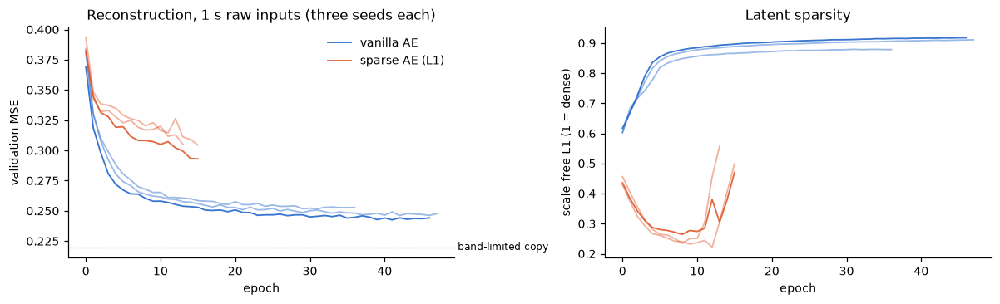

In [2]:
def summarize(names):
    """Mean ± SD over seeds of each model's validation metrics, then the per-seed table."""
    rows = []
    for name in names:
        for seed in SEEDS:
            s = runs[(name, seed)]['summary']
            rows.append({'model': name, 'seed': seed, 'best epoch': s['best_epoch'], 'epochs run': s['epochs_run'],
                         'val MSE': s['val_mse'], 'val scale-free L1': s['val_penalty'], 'values > 0': s['val_active_fraction'],
                         'dead units (of 32)': s['val_dead_units'], 'minutes': s['minutes']})
    per_seed = pd.DataFrame(rows)
    cols = ['val MSE', 'val scale-free L1', 'values > 0', 'dead units (of 32)', 'best epoch']
    stats = per_seed.groupby('model', sort = False)[cols].agg(['mean', 'std'])
    fmt = {'dead units (of 32)': '{:.1f}', 'best epoch': '{:.0f}'}
    print('Mean ± SD over three seeds (validation participants, ID-safe windows)')
    display(pd.DataFrame({c: stats[(c, 'mean')].map(fmt.get(c, '{:.3f}').format) + ' ± '
                          + stats[(c, 'std')].map(fmt.get(c, '{:.3f}').format) for c in cols}))
    display(per_seed.set_index(['model', 'seed']).round(4))


def plot_curves(names, reference, title):
    """Validation MSE and sparsity per epoch, three seeds per model; ``reference`` is the band-limited copy's MSE."""
    fig, axes = plt.subplots(1, 2, figsize = (11, 3.4))
    colors = dict(zip(names, ['#2266cc', '#e0572b']))
    for (name, seed), r in runs.items():
        if name in names:
            h = r['history']
            for ax, col in zip(axes, ('val_mse', 'val_penalty')):
                ax.plot(h['epoch'], h[col], color = colors[name], lw = 1.2, alpha = .9 if seed == SHOWN_SEED else .45,
                        label = name if (seed == SHOWN_SEED and col == 'val_mse') else None)
    axes[0].axhline(reference, color = 'k', lw = .7, ls = '--')
    axes[0].text(axes[0].get_xlim()[1], reference, ' band-limited copy', va = 'center', fontsize = 8)
    axes[0].set(xlabel = 'epoch', ylabel = 'validation MSE', title = f'Reconstruction, {title}')
    axes[1].set(xlabel = 'epoch', ylabel = 'scale-free L1 (1 = dense)', title = 'Latent sparsity')
    axes[0].legend(frameon = False); plt.tight_layout(); plt.show()


summarize(RAW_1S)
plot_curves(RAW_1S, 0.22, '1 s raw inputs (three seeds each)')

### 1.1 What each latent unit responds to

The 32 latent values are not 32 separate features: they are 4 convolution filters, each read at 8 time steps across
the window (one per 125 ms for 1 s inputs), labelled *f filter · t step* below. Each cell is a unit's mean value over
a task's windows (every in-task window of the test participants), divided by the unit's largest task mean so each row
spans 0 to 1; rows are ordered by the task they respond to most. An asterisk marks a *novelty unit*: its strongest
task is one the model never trained on, at five times or more its strongest response to a training task. Units that
never fire on these windows are labelled unused.

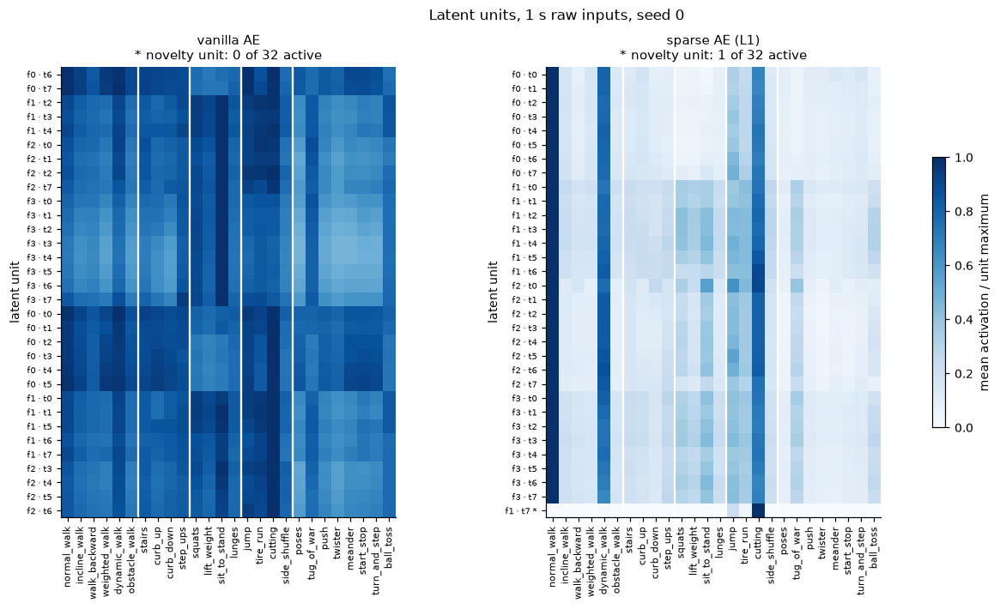

In [3]:
lv.plot_unit_heatmaps({name: runs[(name, SHOWN_SEED)] for name in RAW_1S}, nt.TASK_FAMILIES, nt.ID_SAFE_TASKS,
                      f'Latent units, 1 s raw inputs, seed {SHOWN_SEED}')

## 2. The windows shown

In-task windows of the four test participants that both input settings cover (those with 3 s of
clean history), 250 per task where a task has that many, so no task dominates a
neighbourhood or a principal axis. Seed 0 of each model is shown; the other seeds are summarized in section 1. Views:

- **latent units**: the raw values of the three highest-variance latent units, no projection. What the novelty
  score will actually measure distances in.
- **PCA** of the standardized 32 latent values: the linear directions of largest variance.
- **UMAP** (30 neighbours, minimum distance 0.1, seed 0) of the standardized latent: who is near whom.

Lenses: task family, the tasks one family at a time, controller class (ID-safe = what the models trained on;
OOD-safe and OOD-dangerous were never seen), up / down direction (stairs, ramps and curbs, with level walking for
reference), and the Science Robotics mode a Nature task corresponds to (LG level, RA / RD ramp, SA / SD stairs and
curbs, ST standing poses, TR start-stop transitions).

In [4]:
rng = np.random.default_rng(0)
base = runs[(RAW_1S[0], SHOWN_SEED)]['labels']
longer = runs[(ENGINEERED[0], SHOWN_SEED)]['labels']
common = base[~base['is_train']].merge(longer.loc[~longer['is_train'], ['rec', 'end']], on = ['rec', 'end'])
labels = common.iloc[lv.get_balanced_sample(common, 250, rng)].reset_index(drop = True)
Z = {name: lv.get_aligned_z(runs[(name, SHOWN_SEED)], labels) for name in MODELS}   # every model, the same windows
views = {name: lv.get_views(z, VIEW_CACHE) for name, z in Z.items()}
raw_views, eng_views, rev_views = ({n: views[n] for n in names} for names in (RAW_1S, ENGINEERED, REVISED))
print(f'{len(labels):,} windows, {labels.task.nunique()} tasks, participants {sorted(labels.subject.astype(str).unique())}')
print('latent units shown:', {name: [int(u) for u in v['units']] for name, v in views.items()})
display(labels.groupby('controller_class', observed = True).size().rename('windows').to_frame().T)


def plot_direction_pairs(model_views, title):
    """UMAP: stairs, ramps and curbs in both directions over every other window in grey, one row per model."""
    pairs = {'stairs': ('stairs',), 'ramps': ('incline_walk',), 'curbs': ('curb_up', 'curb_down')}
    fig, axes = plt.subplots(len(model_views), len(pairs), figsize = (12, 3.8 * len(model_views)), squeeze = False)
    tasks, direction = labels['task'].astype(str).to_numpy(), labels['direction'].astype(str).to_numpy()
    for row, (name, v) in zip(axes, model_views.items()):
        pts = v[('UMAP', 2)]
        for ax, (pair, members) in zip(row, pairs.items()):
            ax.scatter(pts[:, 0], pts[:, 1], s = 1, color = lv.BACKGROUND, alpha = .4, rasterized = True)
            for d in ('up', 'down'):
                m = np.isin(tasks, members) & (direction == d)
                ax.scatter(pts[m, 0], pts[m, 1], s = 3, color = lv.DIRECTION_C[d], alpha = .75, label = d, rasterized = True)
            ax.set_title(f'{name} · UMAP · {pair}', fontsize = 9); ax.set_xticks([]); ax.set_yticks([])
            ax.legend(fontsize = 8, markerscale = 3, frameon = False)
    fig.suptitle(title, fontsize = 11); plt.tight_layout(); plt.show()


STYLES = lv.get_task_styles(nt.TASK_FAMILIES)

6,500 windows, 26 tasks, participants ['BT07', 'BT15', 'BT19', 'BT22']
latent units shown: {'vanilla AE': [27, 28, 29], 'sparse AE (L1)': [20, 11, 2], 'vanilla AE · 3 s + spectral': [3, 4, 2], 'sparse AE (L1) · 3 s + spectral': [7, 24, 25], 'sparse AE (L1) · 3 s + spectral · λ 0.1': [2, 3, 4], 'vanilla AE · 3 s + spectral · 8x4 latent': [14, 28, 15], 'sparse AE (L1) · 3 s + spectral · λ 0.1 · 8x4 latent': [15, 31, 11]}


controller_class,ID-safe,OOD-dangerous,OOD-safe
windows,1000,1000,4500


### 3.1 Task family

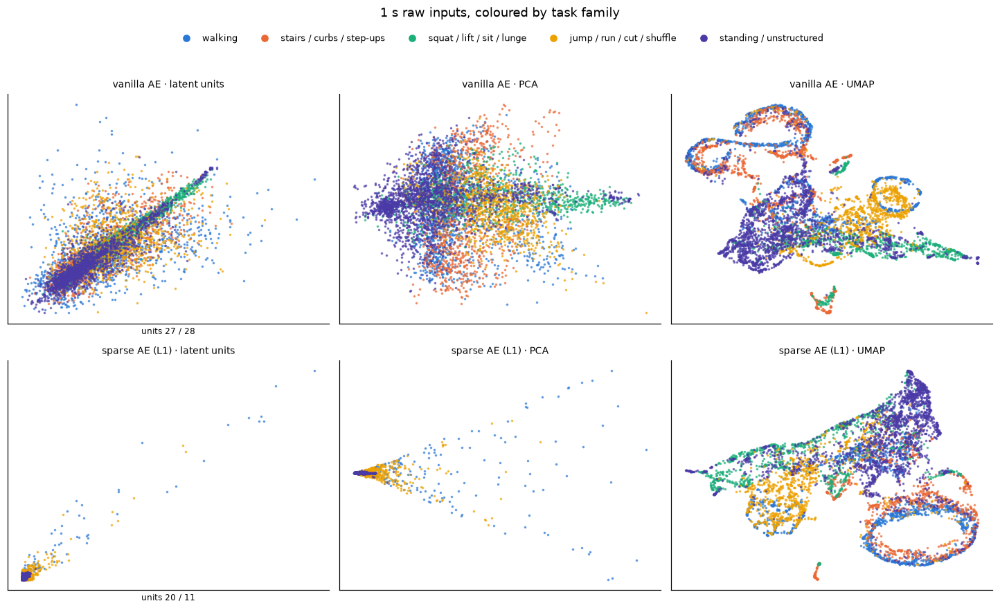

In [5]:
lv.plot_lens_grid(raw_views, labels, 'family', lv.FAMILY_C, '1 s raw inputs, coloured by task family')

### 3.2 Tasks, one family at a time (UMAP)
Each panel colours one family's tasks over every other window in grey.

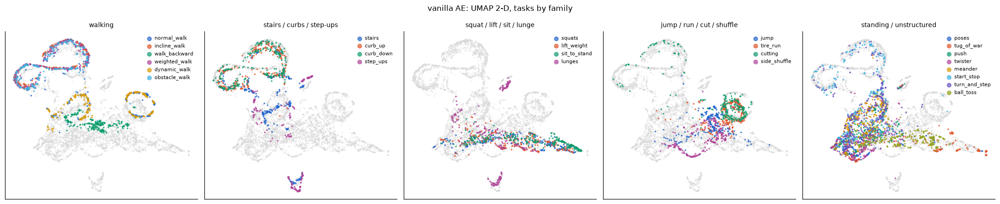

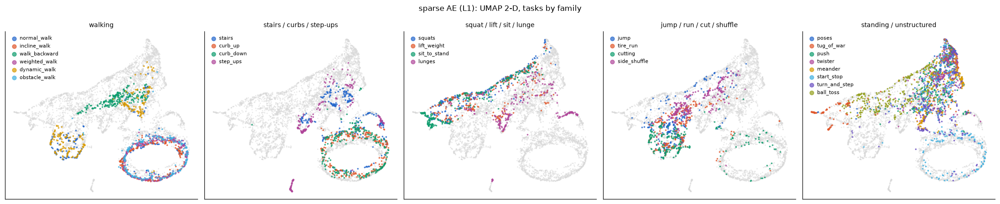

In [6]:
for name in RAW_1S:
    lv.plot_task_panels(views[name][('UMAP', 2)], labels, nt.TASK_FAMILIES, STYLES, f'{name}: UMAP 2-D, tasks by family')

### 3.3 Controller class
ID-safe windows are the kind every model trained on; the other two classes were never seen.

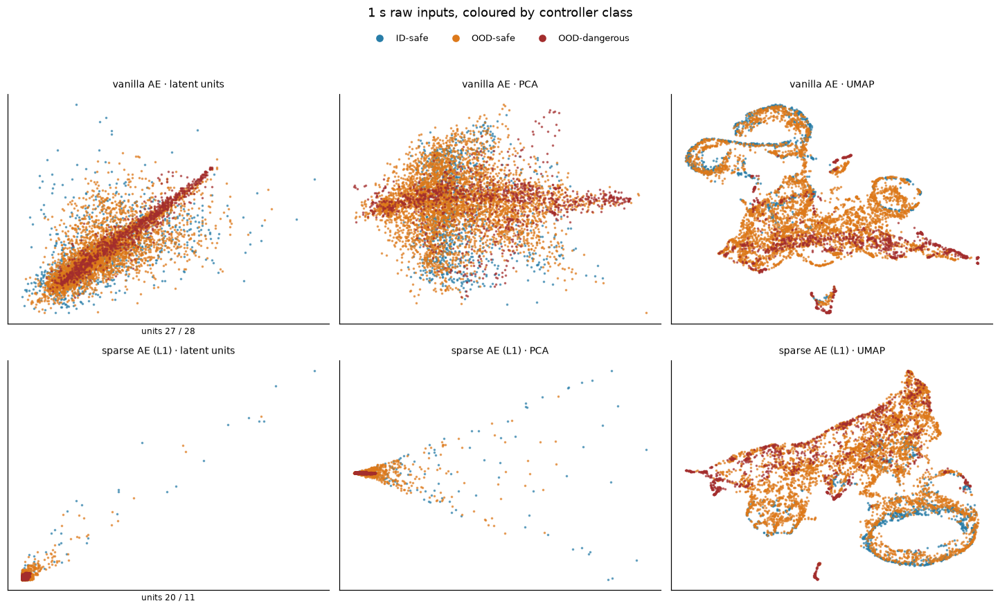

In [7]:
lv.plot_lens_grid(raw_views, labels, 'controller_class', lv.CLASS_C, '1 s raw inputs, coloured by controller class')

### 3.4 Up and down
Stairs and ramps in both directions and single curbs, with level treadmill walking for reference; every other task in
grey. Stair direction is the recording's index parity, ramp direction the sign of the bout's limb power.

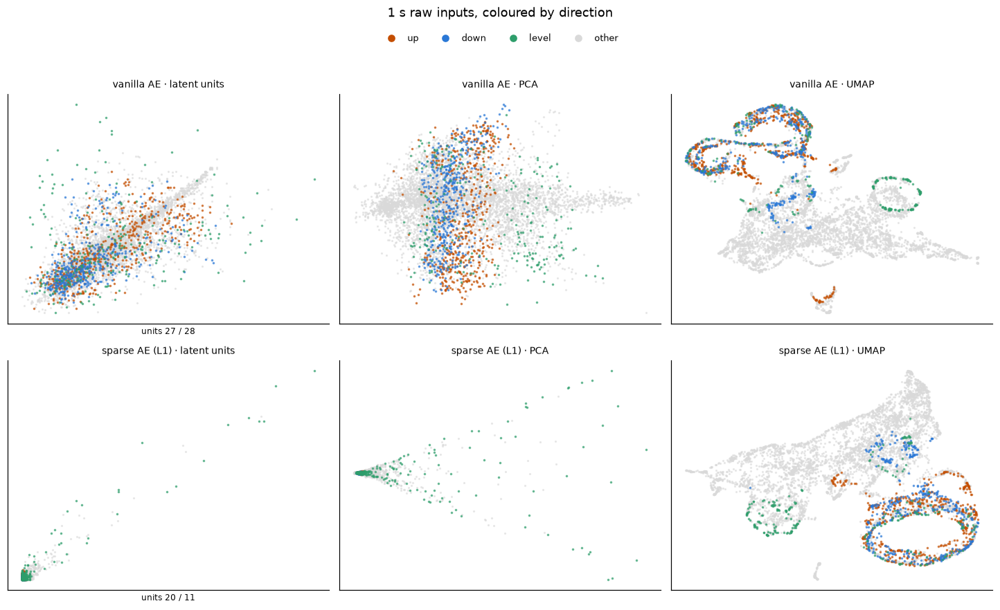

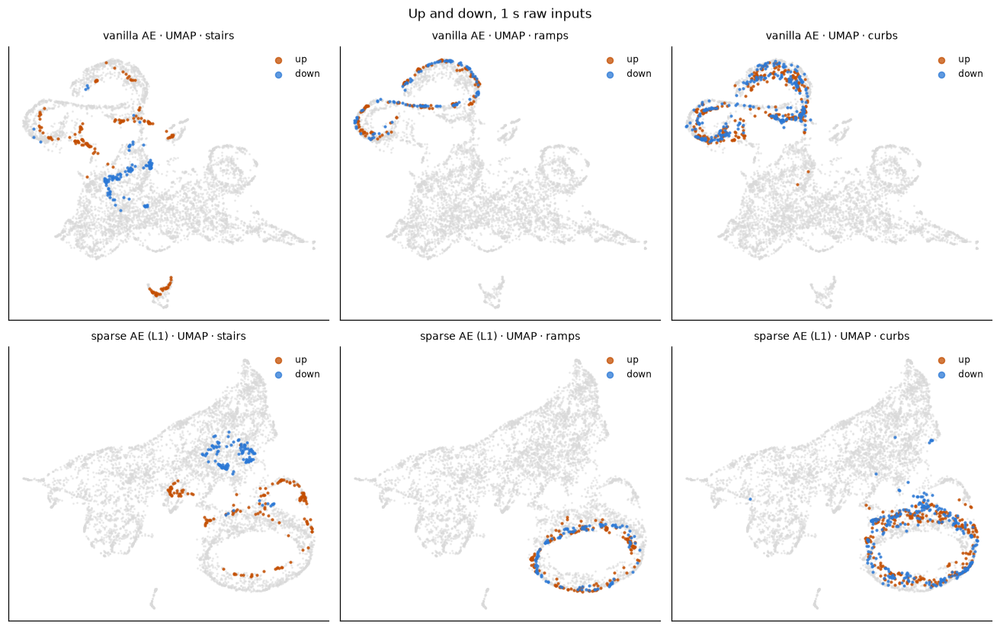

In [8]:
lv.plot_lens_grid(raw_views, labels, 'direction', lv.DIRECTION_C, '1 s raw inputs, coloured by direction')
plot_direction_pairs(raw_views, 'Up and down, 1 s raw inputs')

### 3.5 Shared with the Science Robotics dataset
Nature tasks with a counterpart in the previous dataset, by that mode; Nature-only tasks in grey. Ascent is the darker
shade of each terrain's hue, descent the lighter.

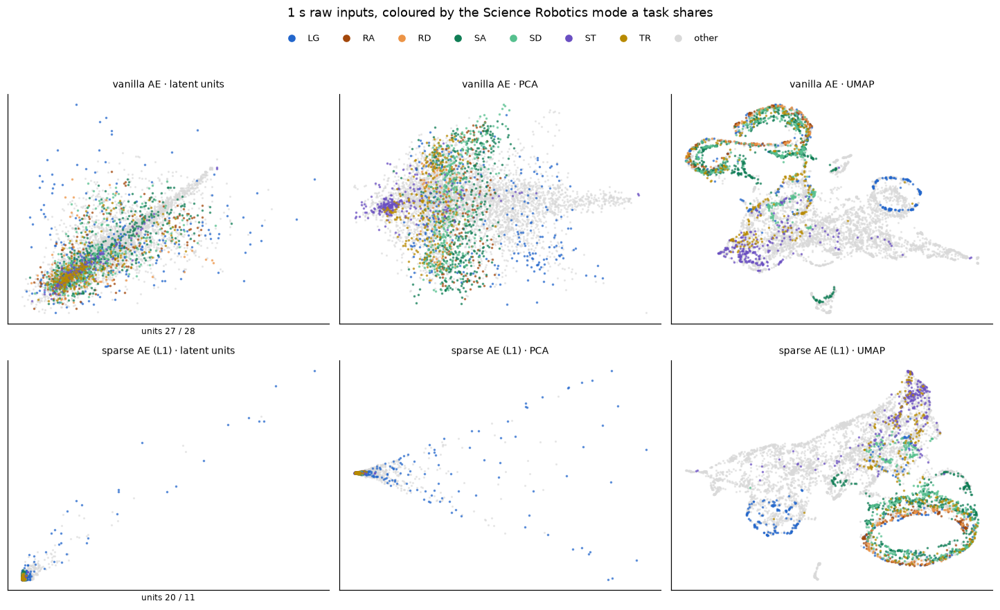

In [9]:
lv.plot_lens_grid(raw_views, labels, 'scirob_mode', lv.SCIROB_C, '1 s raw inputs, coloured by the Science Robotics mode a task shares')

### 3.6 Interactive 3-D, 1 s raw inputs

One figure per model. The dropdown picks the view (latent units, PCA, UMAP) and the lens; drag to rotate, scroll to
zoom, click a legend entry to hide it, double-click to isolate it. In the task lens colour is the family and the marker
shape the task within it; hover shows task, participant and direction. Each view shows 80 windows per task (2,080), the
same windows in every view and every model. Each figure is also saved as a standalone page in `interactive/` beside this
notebook: open that in a browser if your notebook viewer shows no 3-D.

In [10]:
SHOW = np.sort(np.concatenate([rng.choice(np.flatnonzero(labels['task'].astype(str).to_numpy() == t),
                                           min(80, int((labels['task'] == t).sum())), replace = False)
                                for t in labels['task'].astype(str).unique()]))
LENSES = {'task': ('task', {t: STYLES[t]['family'] for ts in nt.TASK_FAMILIES.values() for t in ts}),
          'family': ('family', lv.FAMILY_C), 'controller class': ('controller_class', lv.CLASS_C),
          'direction': ('direction', lv.DIRECTION_C), 'shared with Science Robotics': ('scirob_mode', lv.SCIROB_C)}
SYMBOL = {t: s['symbol'] for t, s in STYLES.items()}
INTERACTIVE = REPO / 'notebooks' / 'nature' / 'model_exploration' / 'onboard' / 'interactive'
CONFIG = {'scrollZoom': True, 'displaylogo': False}


def show_3d(name):
    """One model's interactive 3-D figure (dropdown: view x lens), shown here and saved as a standalone page."""
    model_views = {k: v[SHOW] for k, v in views[name].items() if k != 'units'}
    fig = lv.build_3d({name: model_views}, labels.iloc[SHOW].reset_index(drop = True), LENSES, SYMBOL, name)
    INTERACTIVE.mkdir(exist_ok = True)
    path = INTERACTIVE / f"{re.sub(r'[^a-z0-9]+', '_', name.lower().replace('λ', 'lambda')).strip('_')}_3d.html"
    fig.write_html(path, include_plotlyjs = 'cdn', config = CONFIG)
    fig.show(config = CONFIG)
    print('Standalone interactive copy:', path.relative_to(REPO))


for name in RAW_1S:
    show_3d(name)

Standalone interactive copy: notebooks/nature/model_exploration/onboard/interactive/vanilla_ae_3d.html


Standalone interactive copy: notebooks/nature/model_exploration/onboard/interactive/sparse_ae_l1_3d.html


## 4. Engineered features

Notebooks 02 and 03 asked which inputs best separate the tasks and controller classes across people, and both put the
same set first: the raw channels over **3 s** plus the **spectral family** (dominant frequency, spectral entropy and
stride regularity per leg, and step regularity).

| feature set | boosted trees, nb 02 (task family / controller class) | k-NN in UMAP 3-D, nb 03 (task family / controller class) |
|---|---|---|
| raw, 1 s | 0.906 / 0.843 | 0.807 / 0.726 |
| raw + all engineered, 1 s | 0.939 / 0.876 | 0.846 / 0.770 |
| raw, 3 s | 0.945 / 0.889 | 0.885 / 0.845 |
| **raw, 3 s + spectral** | **0.950 / 0.898** | **0.912 / 0.872** |

Jerk and the high-frequency ratios were left out because they blurred the embeddings; polar phase and thigh pitch added
under a point.

For the autoencoder this becomes the 16 raw channels over 3 s (600 samples) plus the seven spectral features at the
window end, each held constant across the window as an extra channel: 23 inputs. The second pooling stage grows from 5
to 15, so the latent stays 4 filters x 8 steps = 32 values (each step now 375 ms) and only the inputs differ from
section 1. Same participants and training class; 111,369 training windows (those with 3 s of clean history); λ 0.3.

**Two training fixes, applied to all four models (all were retrained with them):**

- BatchNorm statistics are recomputed exactly over 50 training batches before each validation. Their running
  averages drifted when latent units fire rarely, so a sparse model's validation error jumped by up to 0.09 between
  epochs and early stopping kept a lucky dip (one checkpoint scored 0.359 with the running statistics and 0.313 with
  exact ones).
- λ ramps up over the first 5 epochs, and early stopping starts once it is at full strength. Without the ramp, one
  3 s seed silenced 24 of its 32 units within two epochs.

**λ check** with these inputs on a 30,000-window subset (40 epochs): against vanilla, λ 0.1 / 0.3 / 1.0 cost +8% /
+15% / +25% validation MSE at scale-free L1 0.23 / 0.13 / 0.06 (5 / 9 / 18 units dead). 0.3 is kept so that the input
setting is the only difference from section 1; 1.0 would also stay within 30% of vanilla but silences over half the units.

Reconstruction errors are not comparable across the two settings: a 3 s window has 23 inputs, 7 of them constant, and
less of it fits through 8 latent steps. For scale, a copy keeping only content below 1.33 Hz (8 steps per 3 s) scores 0.36.

Mean ± SD over three seeds (validation participants, ID-safe windows)


,val MSE,val scale-free L1,values > 0,dead units (of 32),best epoch
model,,,,,
vanilla AE,0.247 ± 0.005,0.902 ± 0.020,0.988 ± 0.019,0.0 ± 0.0,38 ± 6
sparse AE (L1),0.313 ± 0.007,0.249 ± 0.022,0.756 ± 0.069,0.3 ± 0.6,9 ± 1
vanilla AE · 3 s + spectral,0.269 ± 0.002,0.839 ± 0.090,0.917 ± 0.092,0.3 ± 0.6,46 ± 8
sparse AE (L1) · 3 s + spectral,0.306 ± 0.014,0.104 ± 0.032,0.443 ± 0.028,13.0 ± 1.0,48 ± 19


best epoch  epochs run  val MSE  val scale-free L1  values > 0  dead units (of 32)  minutes
model                           seed                                                                                             
vanilla AE                      0             41          47   0.2426             0.9167      0.9988                   0     3.71
                                1             31          37   0.2518             0.8794      0.9664                   0     2.53
                                2             42          48   0.2461             0.9096      0.9984                   0     3.43
sparse AE (L1)                  0             10          16   0.3050             0.2741      0.8327                   0     1.58
                                1             10          16   0.3164             0.2372      0.7368                   1     1.61
                                2              8          14   0.3167             0.2345      0.6980                   0     1.02
vanilla AE · 3 s + spectral     0             43          49   0.2714             0.8916      0.9607                   0     5.16
                                1             39          45   0.2682             0.7359      0.8112                   1     4.73
                                2             55          61   0.2669             0.8902      0.9798                   0     6.39
sparse AE (L1) · 3 s + spectral 0             38          44   0.3073             0.1034      0.4109                  14     4.64
                                1             70          76   0.2911             0.0732      0.4560                  13     7.54
                                2             35          41   0.3191             0.1364      0.4635                  12     4.21

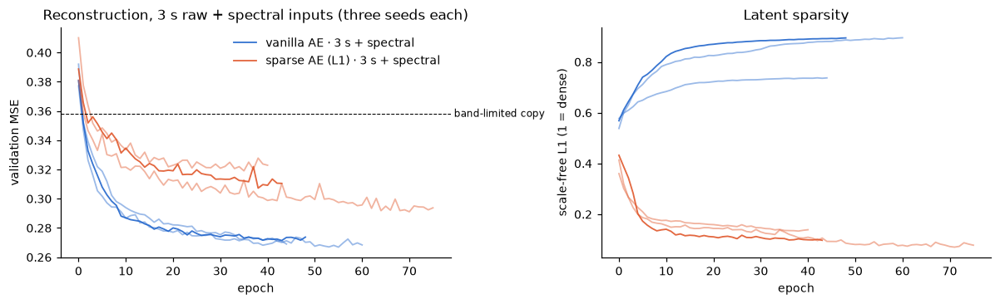

In [11]:
summarize(RAW_1S + ENGINEERED)
plot_curves(ENGINEERED, 0.358, '3 s raw + spectral inputs (three seeds each)')

### 4.1 What each latent unit responds to
As in 1.1. With 3 s inputs each of the 8 time steps covers 375 ms.

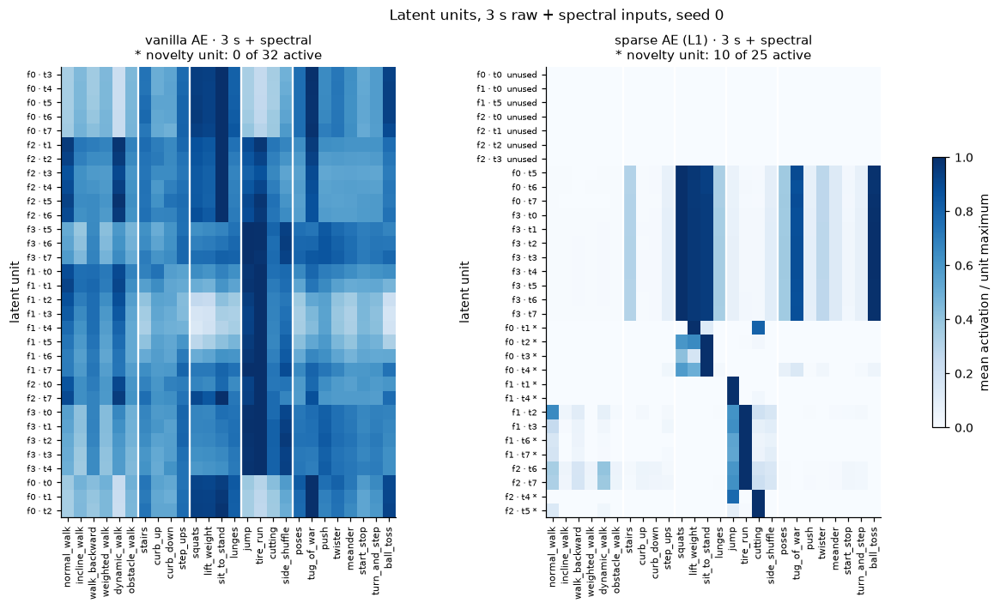

In [12]:
lv.plot_unit_heatmaps({name: runs[(name, SHOWN_SEED)] for name in ENGINEERED}, nt.TASK_FAMILIES, nt.ID_SAFE_TASKS,
                      f'Latent units, 3 s raw + spectral inputs, seed {SHOWN_SEED}')

Novelty units in every seed (active units whose strongest task is unseen, at five times or more their strongest
training-task mean):

In [13]:
rows = []
for (name, seed), r in runs.items():
    if name in RAW_1S + ENGINEERED:
        test = ~r['labels']['is_train'].to_numpy()
        means = pd.DataFrame(r['z'][test]).groupby(r['labels']['task'].astype(str).to_numpy()[test]).mean()
        rows.append({'model': name, 'seed': seed, 'active units': int((means.max() > 1e-6).sum()),
                     'novelty units': int(lv.get_novelty_units(means, nt.ID_SAFE_TASKS).sum())})
counts = pd.DataFrame(rows).pivot(index = 'model', columns = 'seed').loc[RAW_1S + ENGINEERED]
display(counts)

active units         novelty units        
seed                                       0   1   2             0   1   2
model                                                                     
vanilla AE                                32  32  32             0   1   0
sparse AE (L1)                            32  32  32             1   2   3
vanilla AE · 3 s + spectral               32  31  32             0   0   0
sparse AE (L1) · 3 s + spectral           25  31  26            10  24  21

### 4.2 Side by side: 1 s raw against 3 s raw + spectral (UMAP)
The same windows, the same UMAP settings; rows are the two models, columns the two input settings.

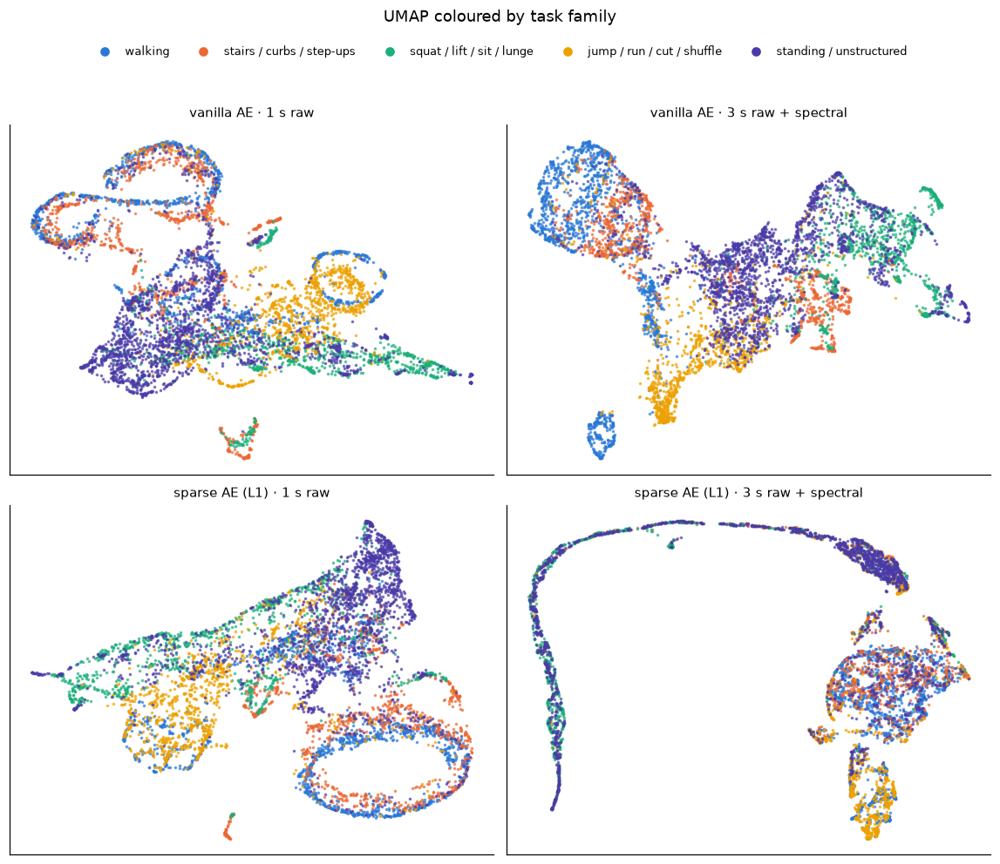

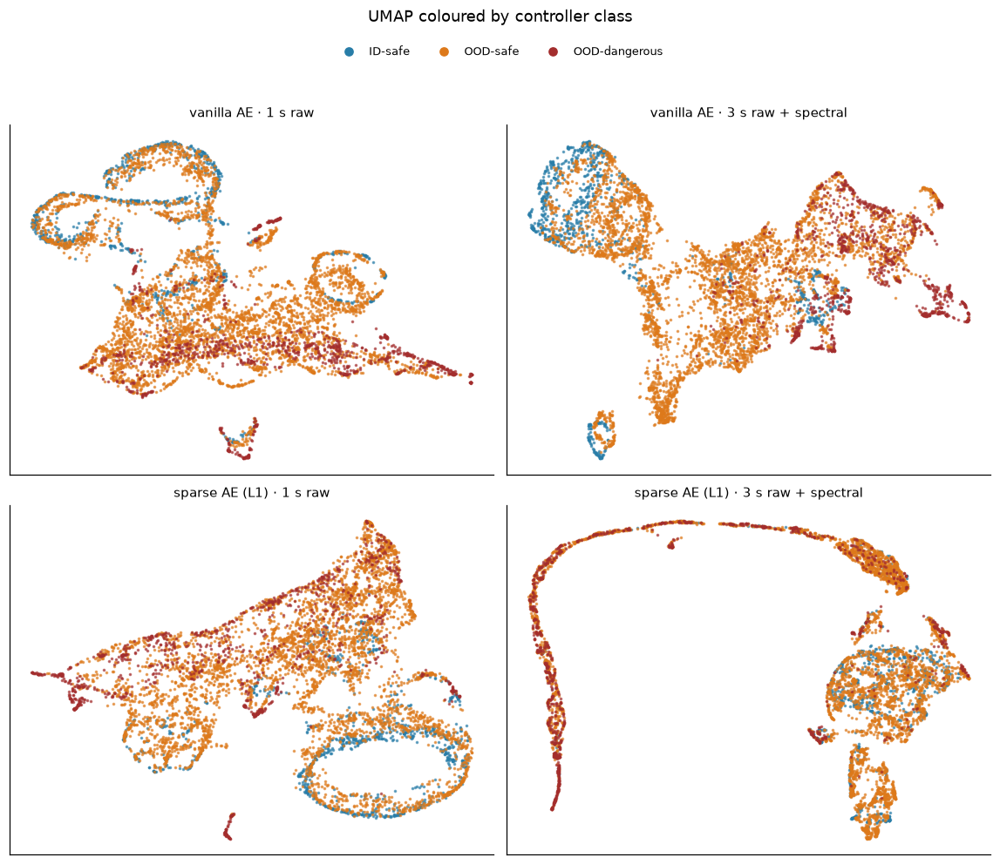

In [14]:
def plot_setting_compare(column, palette, title):
    fig, axes = plt.subplots(2, 2, figsize = (10.5, 9))
    values = labels[column].astype(str).to_numpy()
    rest = ~np.isin(values, list(palette))
    for r, variant in enumerate(('vanilla AE', 'sparse AE (L1)')):
        for c, (setting, name) in enumerate((('1 s raw', variant), ('3 s raw + spectral', f'{variant} · 3 s + spectral'))):
            ax, pts = axes[r, c], views[name][('UMAP', 2)]
            ax.scatter(pts[rest, 0], pts[rest, 1], s = 1.2, color = lv.BACKGROUND, alpha = .5, rasterized = True)
            for lab, color in palette.items():
                m = values == lab
                ax.scatter(pts[m, 0], pts[m, 1], s = 1.8, color = color, alpha = .6, rasterized = True)
            ax.set_title(f'{variant} · {setting}', fontsize = 9.5); ax.set_xticks([]); ax.set_yticks([])
    handles = [plt.Line2D([], [], marker = 'o', ls = '', color = col, label = lab, markersize = 6) for lab, col in palette.items()]
    fig.legend(handles = handles, loc = 'upper center', bbox_to_anchor = (.5, .965), ncol = min(len(handles), 6), fontsize = 8.5, frameon = False)
    fig.suptitle(title, y = .995, fontsize = 12); plt.tight_layout(rect = (0, 0, 1, .93)); plt.show()


plot_setting_compare('family', lv.FAMILY_C, 'UMAP coloured by task family')
plot_setting_compare('controller_class', lv.CLASS_C, 'UMAP coloured by controller class')

### 4.3 Every view and lens, 3 s raw + spectral inputs

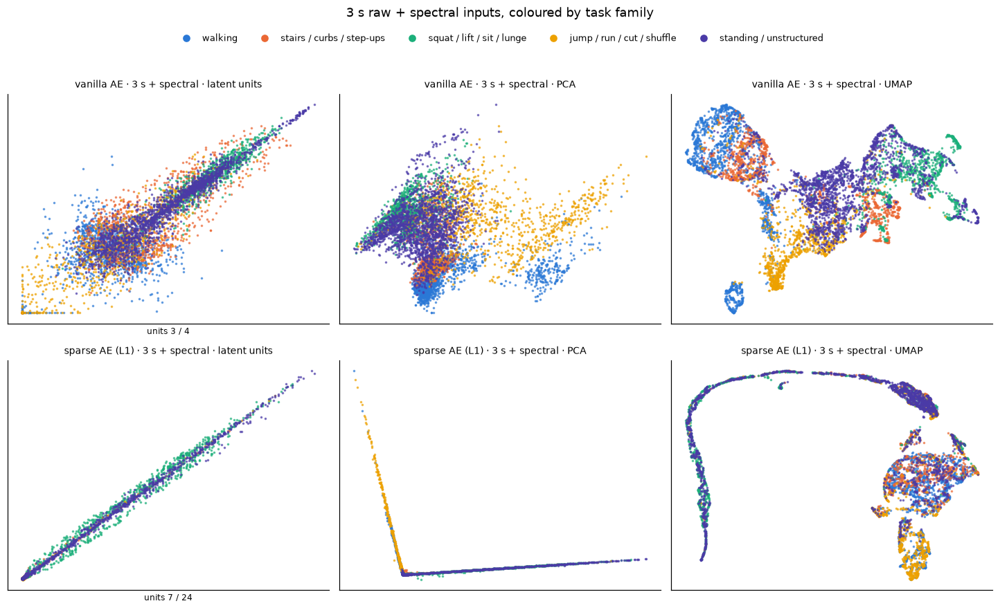

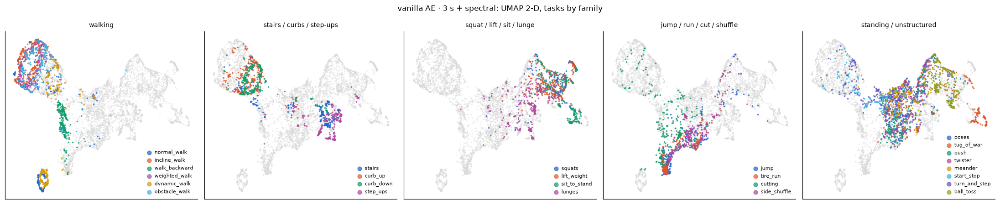

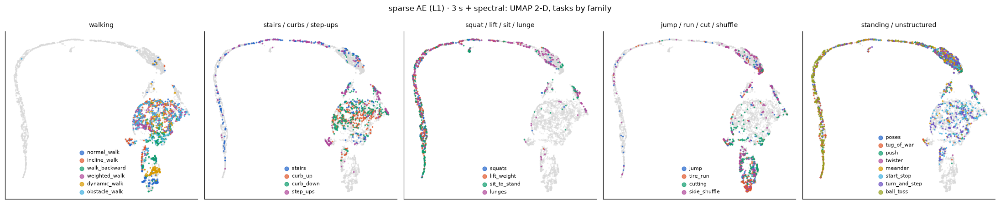

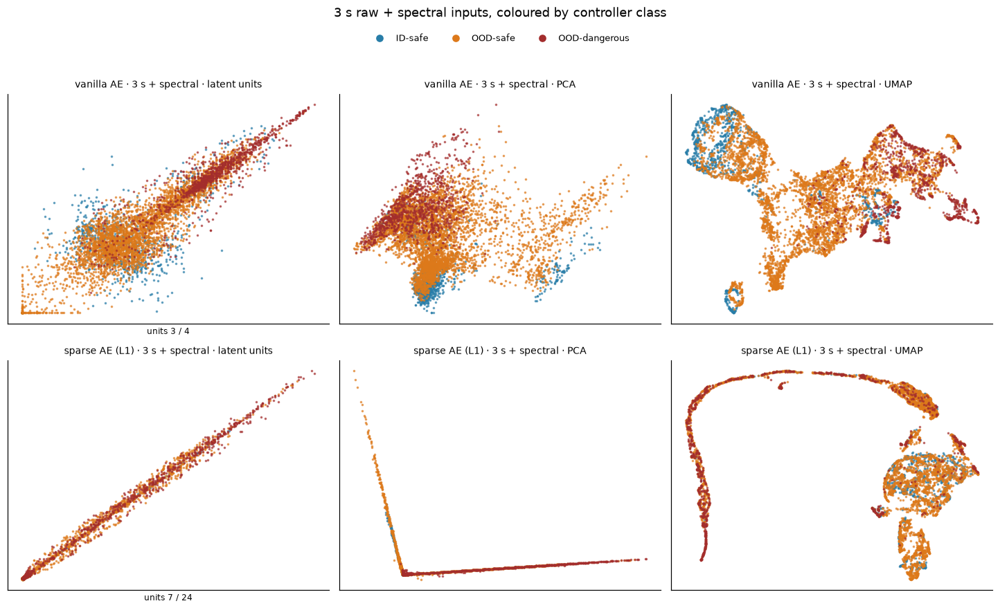

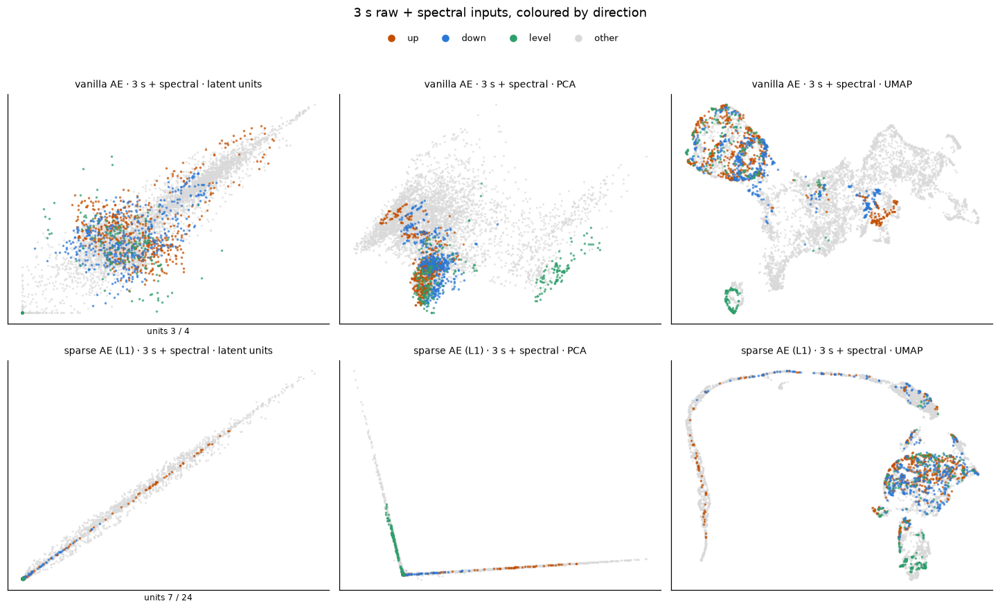

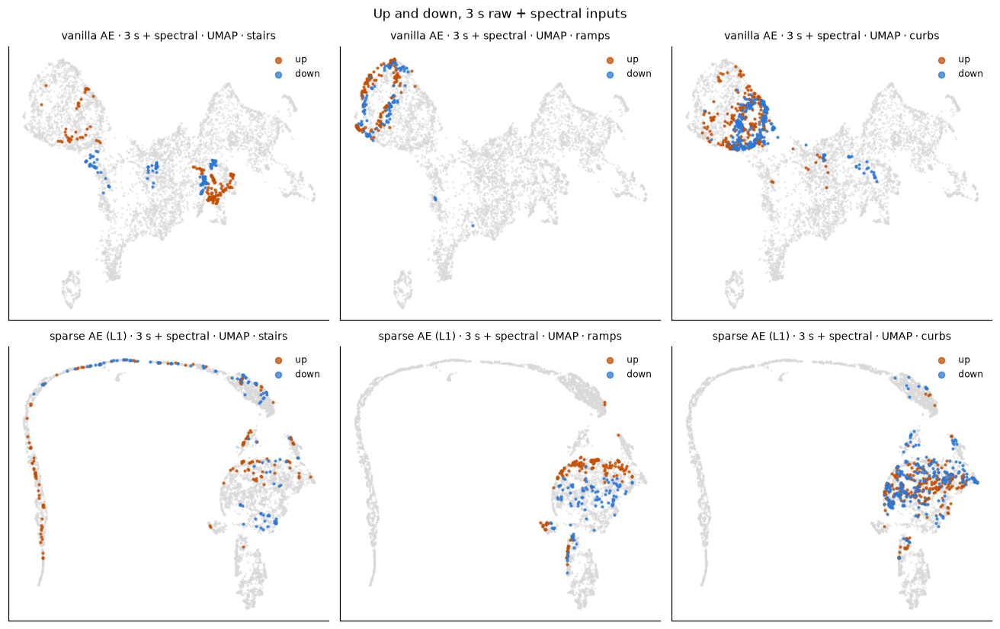

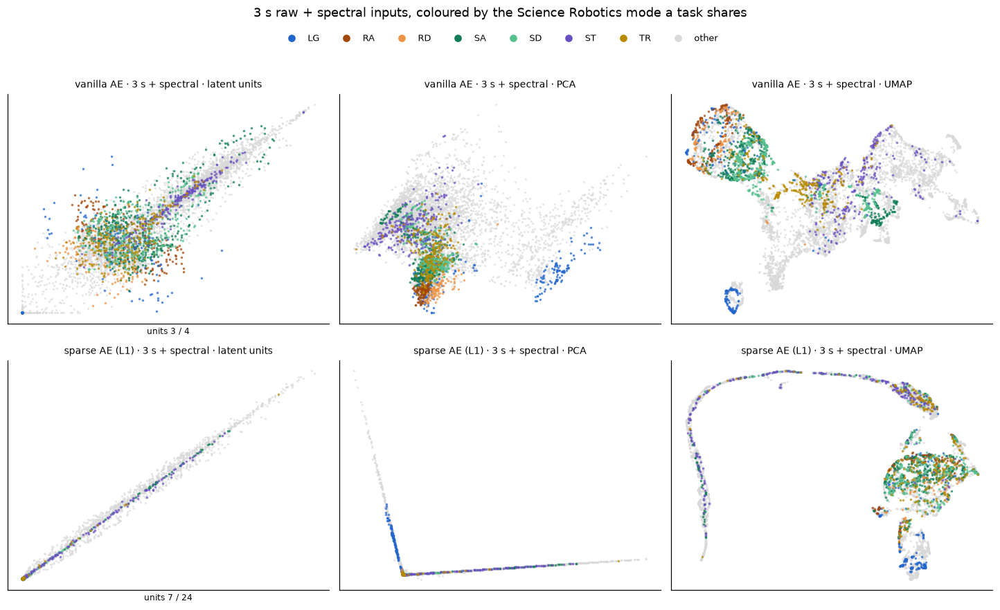

In [15]:
lv.plot_lens_grid(eng_views, labels, 'family', lv.FAMILY_C, '3 s raw + spectral inputs, coloured by task family')
for name in ENGINEERED:
    lv.plot_task_panels(views[name][('UMAP', 2)], labels, nt.TASK_FAMILIES, STYLES, f'{name}: UMAP 2-D, tasks by family')
lv.plot_lens_grid(eng_views, labels, 'controller_class', lv.CLASS_C, '3 s raw + spectral inputs, coloured by controller class')
lv.plot_lens_grid(eng_views, labels, 'direction', lv.DIRECTION_C, '3 s raw + spectral inputs, coloured by direction')
plot_direction_pairs(eng_views, 'Up and down, 3 s raw + spectral inputs')
lv.plot_lens_grid(eng_views, labels, 'scirob_mode', lv.SCIROB_C, '3 s raw + spectral inputs, coloured by the Science Robotics mode a task shares')

### 4.4 Interactive 3-D, 3 s raw + spectral inputs

The same figures for the AE and the AE (L1) trained on 3 s raw + spectral inputs, on the same 2,080 windows as 3.6, so
switching between the two sections moves the same points. Standalone copies are in `interactive/` as well.

In [16]:
for name in ENGINEERED:
    show_3d(name)

Standalone interactive copy: notebooks/nature/model_exploration/onboard/interactive/vanilla_ae_3_s_spectral_3d.html


Standalone interactive copy: notebooks/nature/model_exploration/onboard/interactive/sparse_ae_l1_3_s_spectral_3d.html


### 4.5 What changed

- **Walking becomes one place, not a cycle.** A 3 s window spans two or three strides, so where in the stride it ends
  matters less than which movement it is; the rings of section 3 collapse, and the latent organizes by movement type.
- **The sparse model uses its units as detectors of the unfamiliar.** Trained only on walking and stairs, most of its
  active units stay near zero for that movement and switch on for specific unseen kinds: running and jumping above
  all, then sit-to-stand, cutting, step-ups and lifting. In seed 0 a further block responds to the slow, posture-driven
  tasks (squats, lifting, sit-to-stand, ball toss, tug of war) but also weakly to stairs, so it is not counted. The
  vanilla model spreads every task over every unit.
- **Rhythm features make the sparse code person-independent.** Spectral features describe rhythm rather than each
  person's signal shape, and with them the sparse code keeps its sparsity on new participants; without them it fits the
  training people.
- **Still open.** Curbs do not separate by direction, and sit-to-stand (OOD-dangerous) still neighbours squats
  (OOD-safe): movement geometry alone does not define the controller classes.

## 5. Lower sparsity and a reshaped latent

The λ 0.3 sparse model's latent-units view (section 4.3) puts every window on one straight line: its two
highest-variance units carry the same signal (|r| 1.00 in all three seeds). That looked like too strong a sparsity
penalty, so a lower penalty and one structural change were tried.

**Diagnosis.** Both 3 s latents are redundant along time: neighbouring steps of one filter correlate at |r| 0.49
(sparse) to 0.65 (vanilla), because each step covers 375 ms and the slow, posture-driven tasks barely change within
3 s. Both spread windows over only about 4 effective directions out of 32 (the participation ratio of the active
units' correlation spectrum: 1 when every unit carries the same signal).

**Screen** (30,000-window training subset, 40 epochs, validation participants):

| configuration | val MSE | scale-free L1 | effective directions | novelty units |
|---|---|---|---|---|
| vanilla, 4 x 8 | 0.289 | 0.80 | 2.3 | 0 |
| sparse λ 0.3, 4 x 8 (section 4) | 0.325 | 0.08 | 1.3 | 20 |
| sparse λ 0.1, 4 x 8 | 0.308 | 0.32 | 2.4 | 1 |
| sparse λ 0.03, 4 x 8 | 0.300 | 0.56 | 2.8 | 1 |
| vanilla, 8 x 4 | 0.380 | 0.62 | 2.7 | 1 |
| sparse λ 0.1, 8 x 4 | 0.431 | 0.19 | 4.5 | 8 |

Two finalists were then trained in full, three seeds each, with the protocol and windows of section 4: **λ 0.1** on the
same latent (a lower penalty), and **λ 0.1 on a latent reshaped to 8 filters x 4 time steps** (still 32 values: fewer,
longer steps and twice the filters), with a vanilla AE of the same shape for a fair comparison.

**Criteria, fixed before the full runs.** Better than the λ 0.3 model means more effective directions on the
held-out participants' windows of all tasks, while staying clearly sparse (scale-free L1 at most 0.5), within 30% of
the reconstruction error of a vanilla AE of the same shape, and with sparsity that holds on new people (checked in the
screen, where training and validation values matched for every configuration). Two descriptive measures closer to the
plot that prompted this are reported as well: variance-weighted directions (the same count with units weighted by
their variance, which is what a distance in the raw latent sees) and |r| between the two highest-variance units.

In [17]:
rows = []
for name in ENGINEERED + REVISED:
    for seed in SEEDS:
        r = runs[(name, seed)]
        test = ~r['labels']['is_train'].to_numpy()
        z = r['z'][test]
        means = pd.DataFrame(z).groupby(r['labels']['task'].astype(str).to_numpy()[test]).mean()
        rows.append({'model': name, 'seed': seed, 'val MSE': r['summary']['val_mse'], 'val scale-free L1': r['summary']['val_penalty'],
                     'active units': int((z.std(axis = 0) > 1e-6).sum()),
                     'effective directions': lv.get_effective_directions(z),
                     'variance-weighted directions': lv.get_effective_directions(z, standardize = False),
                     'top-unit |r|': lv.get_top_unit_correlation(z),
                     'novelty units': int(lv.get_novelty_units(means, nt.ID_SAFE_TASKS).sum())})
latent_stats = pd.DataFrame(rows)
cols = [c for c in latent_stats if c not in ('model', 'seed')]
agg = latent_stats.groupby('model', sort = False)[cols].agg(['mean', 'std'])
fmt = {'active units': '{:.1f}', 'effective directions': '{:.1f}', 'variance-weighted directions': '{:.1f}', 'novelty units': '{:.1f}'}
print('Mean ± SD over three seeds. Directions, top-unit |r| and novelty units: test participants, in-task windows, all tasks.')
display(pd.DataFrame({c: agg[(c, 'mean')].map(fmt.get(c, '{:.3f}').format) + ' ± ' + agg[(c, 'std')].map(fmt.get(c, '{:.3f}').format)
                      for c in cols}))
display(latent_stats.set_index(['model', 'seed']).round(3))

Mean ± SD over three seeds. Directions, top-unit |r| and novelty units: test participants, in-task windows, all tasks.


,val MSE,val scale-free L1,active units,effective directions,variance-weighted directions,top-unit |r|,novelty units
model,,,,,,,
vanilla AE · 3 s + spectral,0.269 ± 0.002,0.839 ± 0.090,31.7 ± 0.6,4.2 ± 1.6,3.4 ± 1.4,0.706 ± 0.421,0.0 ± 0.0
sparse AE (L1) · 3 s + spectral,0.306 ± 0.014,0.104 ± 0.032,27.3 ± 3.2,4.5 ± 1.3,1.2 ± 0.2,0.999 ± 0.001,18.3 ± 7.4
sparse AE (L1) · 3 s + spectral · λ 0.1,0.285 ± 0.003,0.273 ± 0.018,31.7 ± 0.6,3.1 ± 0.8,1.2 ± 0.4,0.999 ± 0.001,4.3 ± 4.9
vanilla AE · 3 s + spectral · 8x4 latent,0.353 ± 0.008,0.612 ± 0.017,32.0 ± 0.0,3.8 ± 0.3,1.8 ± 0.2,0.952 ± 0.033,1.0 ± 1.0
sparse AE (L1) · 3 s + spectral · λ 0.1 · 8x4 latent,0.358 ± 0.006,0.139 ± 0.052,30.7 ± 1.5,4.7 ± 0.8,1.3 ± 0.5,0.905 ± 0.163,17.0 ± 7.8


val MSE  val scale-free L1  active units  effective directions  variance-weighted directions  top-unit |r|  novelty units
model                                              seed                                                                                                                           
vanilla AE · 3 s + spectral                        0       0.271              0.892            32                 5.628                         4.466         0.916              0
                                                   1       0.268              0.736            31                 4.466                         3.875         0.221              0
                                                   2       0.267              0.890            32                 2.450                         1.742         0.980              0
sparse AE (L1) · 3 s + spectral                    0       0.307              0.103            25                 4.122                         1.004         0.998             10
                                                   1       0.291              0.073            31                 5.929                         1.273         1.000             24
                                                   2       0.319              0.136            26                 3.335                         1.343         1.000             21
sparse AE (L1) · 3 s + spectral · λ 0.1            0       0.285              0.265            32                 2.481                         1.009         1.000              1
                                                   1       0.288              0.294            31                 3.925                         1.645         0.998             10
                                                   2       0.281              0.260            32                 2.748                         1.022         0.998              2
vanilla AE · 3 s + spectral · 8x4 latent           0       0.362              0.631            32                 3.513                         1.693         0.939              0
                                                   1       0.346              0.598            32                 4.119                         1.993         0.990              1
                                                   2       0.351              0.607            32                 3.622                         1.566         0.928              2
sparse AE (L1) · 3 s + spectral · λ 0.1 · 8x4 l... 0       0.362              0.094            32                 3.866                         1.910         0.717             26
                                                   1       0.352              0.195            31                 5.508                         1.007         1.000             12
                                                   2       0.361              0.128            29                 4.661                         1.010         0.998             13

**Verdict: neither change is better, so section 4's comparison keeps the λ 0.3 model.**

- **A lower penalty made the latent more redundant, not less.** λ 0.1 drops to 3.1 ± 0.8 effective directions
  (λ 0.3: 4.5 ± 1.3), its two strongest units stay collinear (|r| 1.00), and its novelty units fall from 18 to 4. The
  screen had pointed the other way; with all the training data it reversed.
- **The 8 x 4 latent ties.** Its 4.7 ± 0.8 effective directions are within seed noise of 4.5 ± 1.3. It keeps the
  novelty units (17 ± 8) and loosens the strongest pair in one seed of three (|r| 0.72), but its reconstruction error
  equals its own vanilla's (0.358 against 0.353) and is a third above the 4 x 8 vanilla's (0.269), because 750 ms steps
  lose detail.
- **Every sparse latent concentrates its variance in one block.** Variance-weighted directions are 1.2 to 1.3 for all
  three sparse models: a group of units that fire together on the same windows.

### 5.1 What each latent unit responds to
As in 1.1 and 4.1. The 8 x 4 latent has 8 filters at 4 time steps (750 ms each).

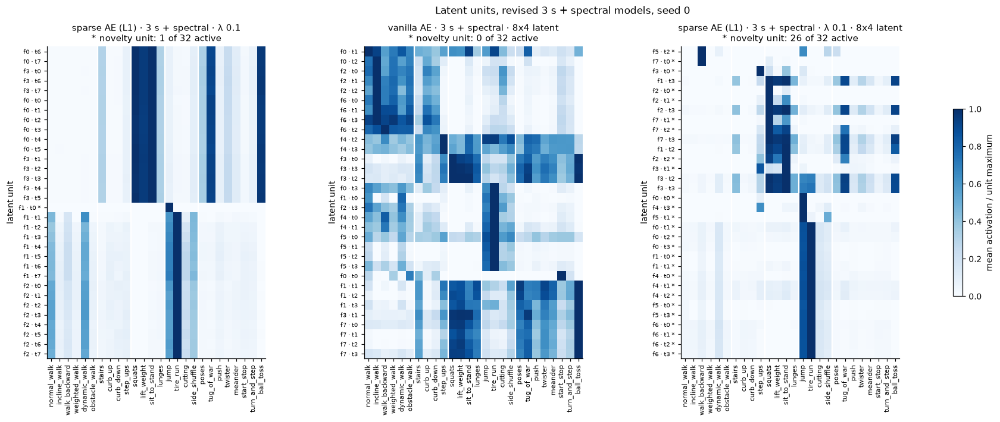

In [18]:
lv.plot_unit_heatmaps({name: runs[(name, SHOWN_SEED)] for name in REVISED}, nt.TASK_FAMILIES, nt.ID_SAFE_TASKS,
                      f'Latent units, revised 3 s + spectral models, seed {SHOWN_SEED}')

### 5.2 Side by side (UMAP)
Top row: the 4 x 8 latent (vanilla, λ 0.3 as in section 4, λ 0.1). Bottom row: the 8 x 4 latent (vanilla, λ 0.1).

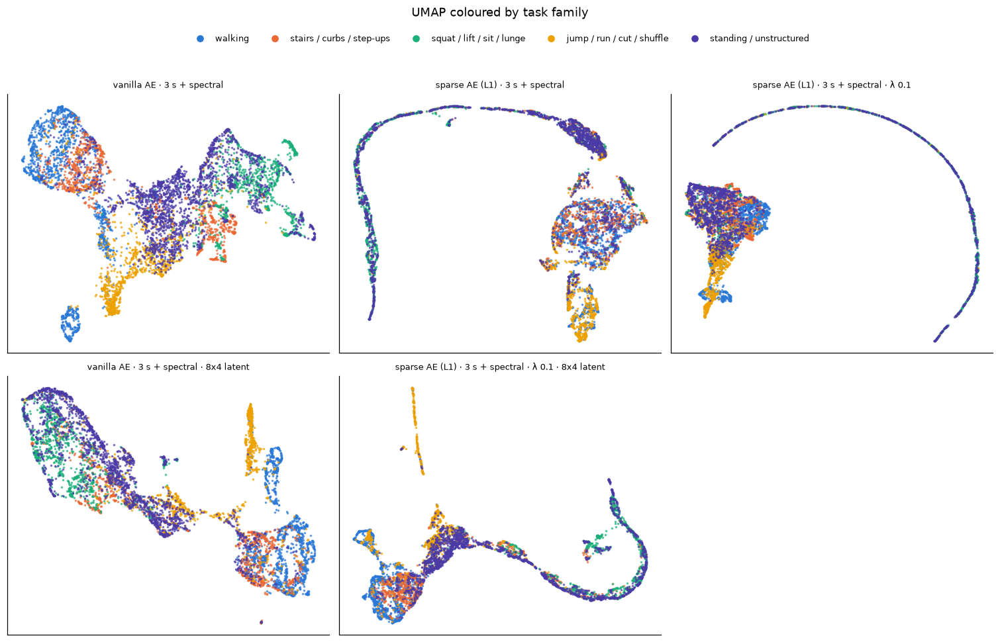

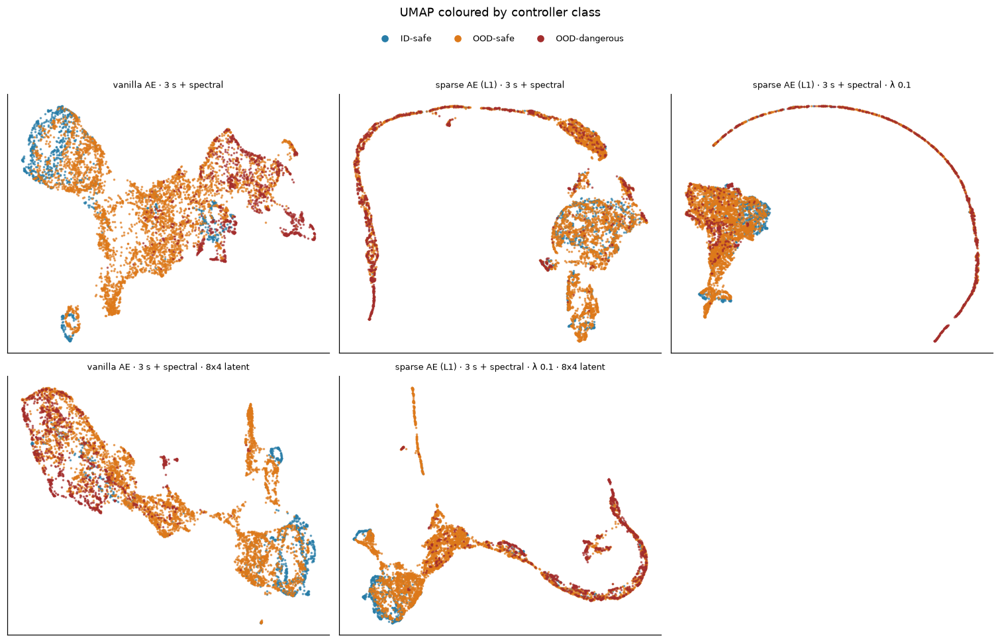

In [19]:
def plot_umap_grid(rows, column, palette, title):
    """UMAP of several models on the same windows; one row of panels per list of model names."""
    ncol = max(len(r) for r in rows)
    fig, axes = plt.subplots(len(rows), ncol, figsize = (4.6 * ncol, 4.4 * len(rows)), squeeze = False)
    values = labels[column].astype(str).to_numpy()
    rest = ~np.isin(values, list(palette))
    for r, names in enumerate(rows):
        for c in range(ncol):
            ax = axes[r, c]
            if c >= len(names):
                ax.axis('off')
            else:
                pts = views[names[c]][('UMAP', 2)]
                ax.scatter(pts[rest, 0], pts[rest, 1], s = 1.2, color = lv.BACKGROUND, alpha = .5, rasterized = True)
                for lab, color in palette.items():
                    m = values == lab
                    ax.scatter(pts[m, 0], pts[m, 1], s = 1.8, color = color, alpha = .6, rasterized = True)
                ax.set_title(names[c], fontsize = 8.5); ax.set_xticks([]); ax.set_yticks([])
    handles = [plt.Line2D([], [], marker = 'o', ls = '', color = col, label = lab, markersize = 6) for lab, col in palette.items()]
    fig.legend(handles = handles, loc = 'upper center', bbox_to_anchor = (.5, .965), ncol = min(len(handles), 6), fontsize = 8.5, frameon = False)
    fig.suptitle(title, y = .995, fontsize = 12); plt.tight_layout(rect = (0, 0, 1, .93)); plt.show()


GRID = [[ENGINEERED[0], ENGINEERED[1], REVISED[0]], [REVISED[1], REVISED[2]]]
plot_umap_grid(GRID, 'family', lv.FAMILY_C, 'UMAP coloured by task family')
plot_umap_grid(GRID, 'controller_class', lv.CLASS_C, 'UMAP coloured by controller class')

### 5.3 Every view and lens, revised models

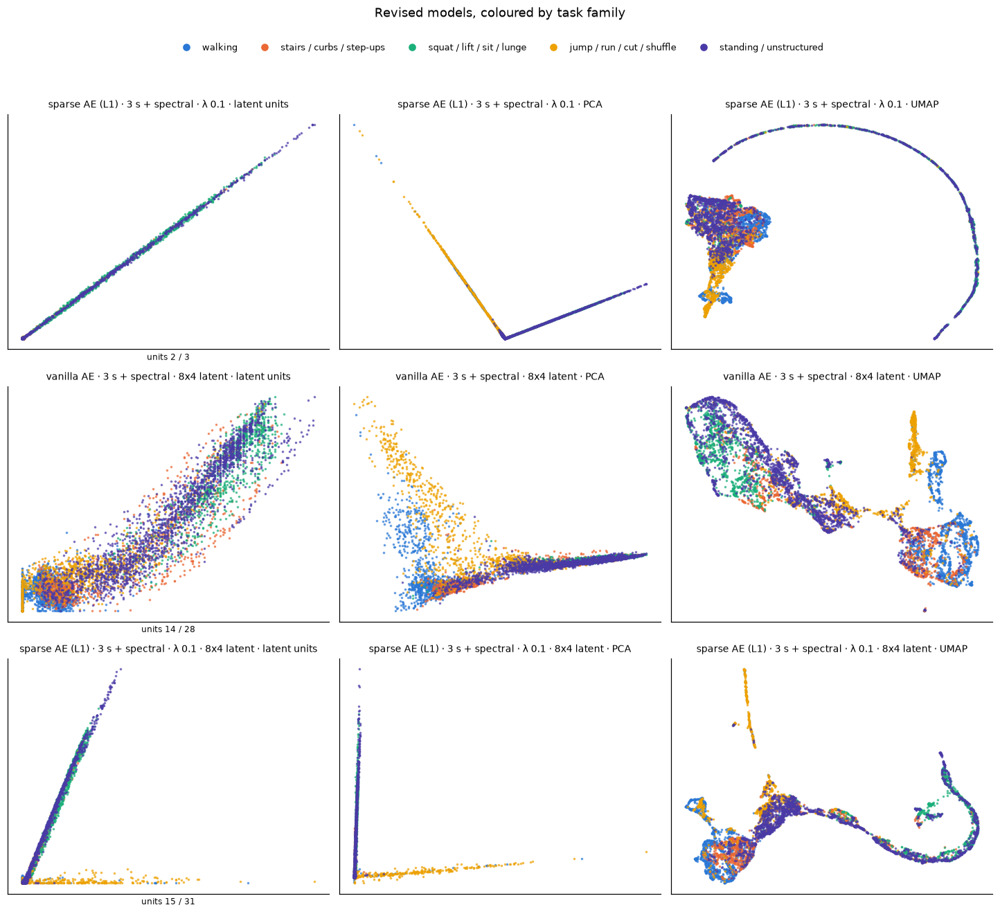

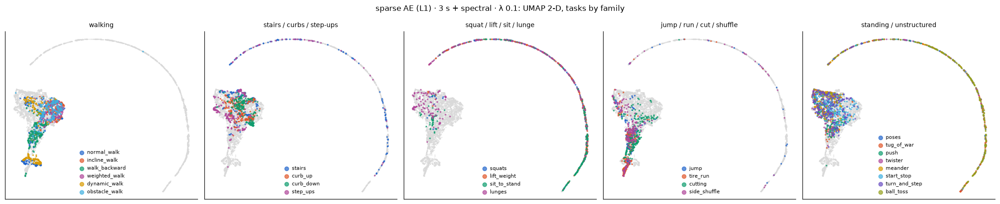

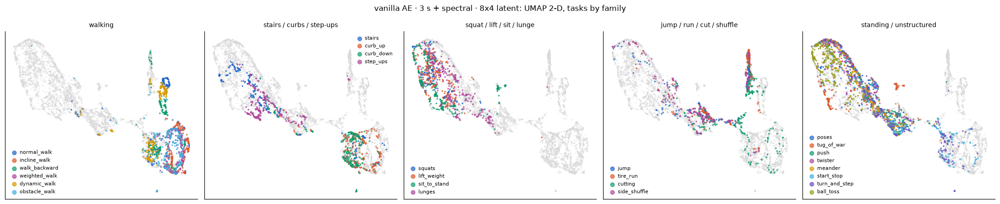

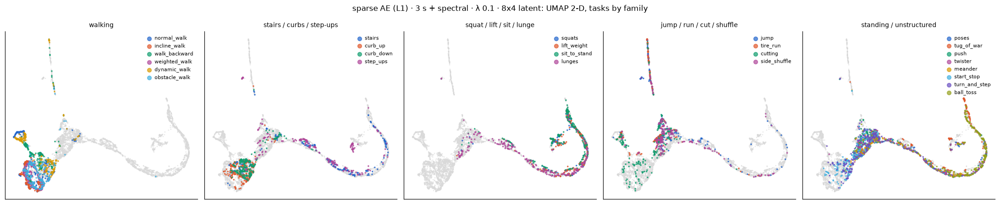

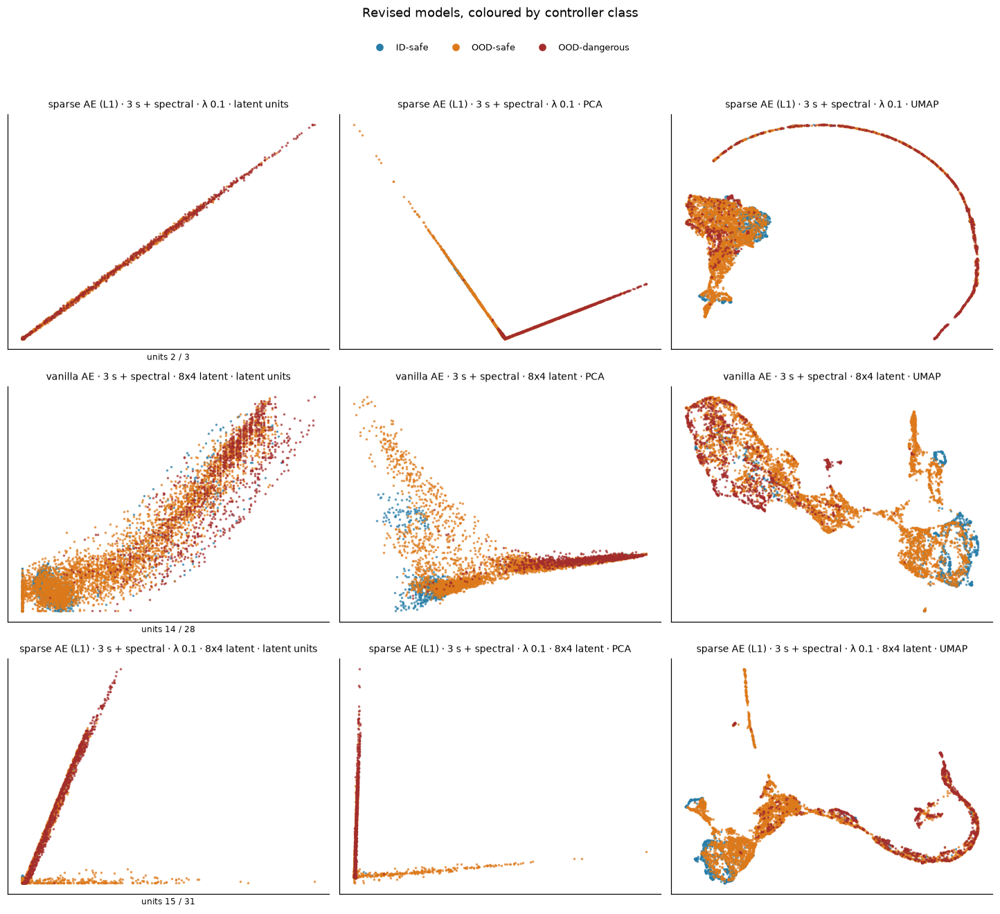

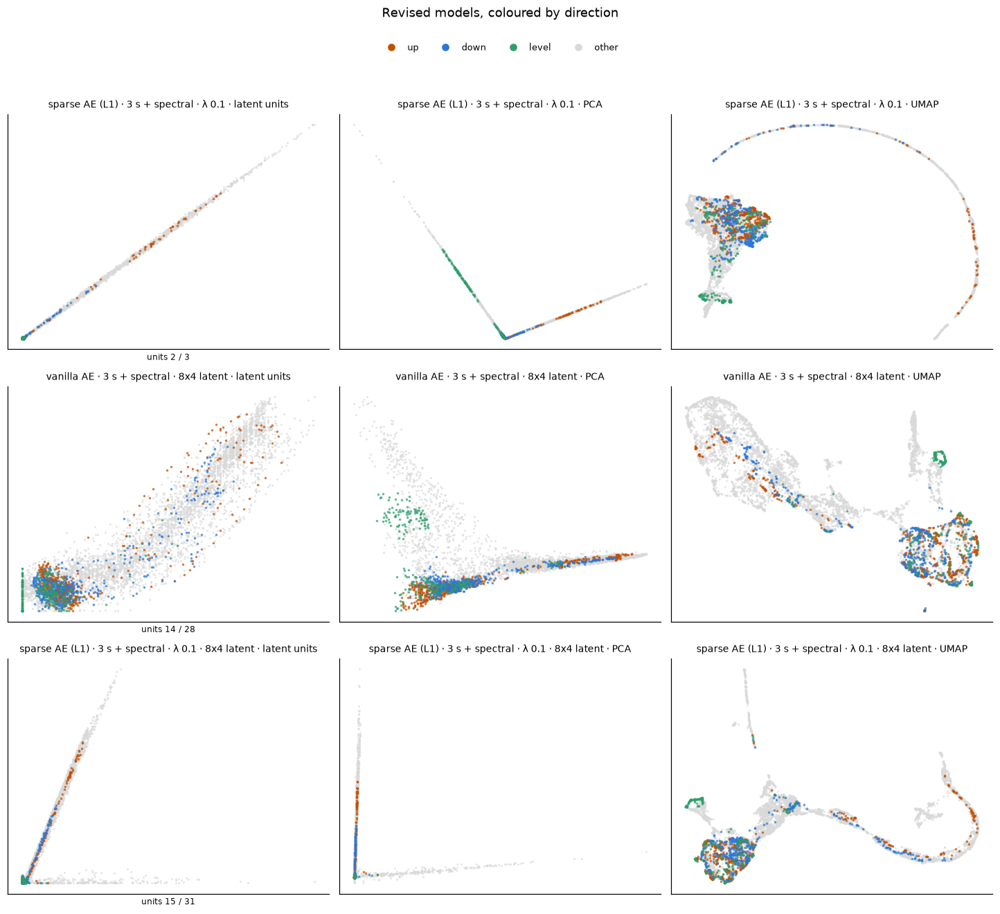

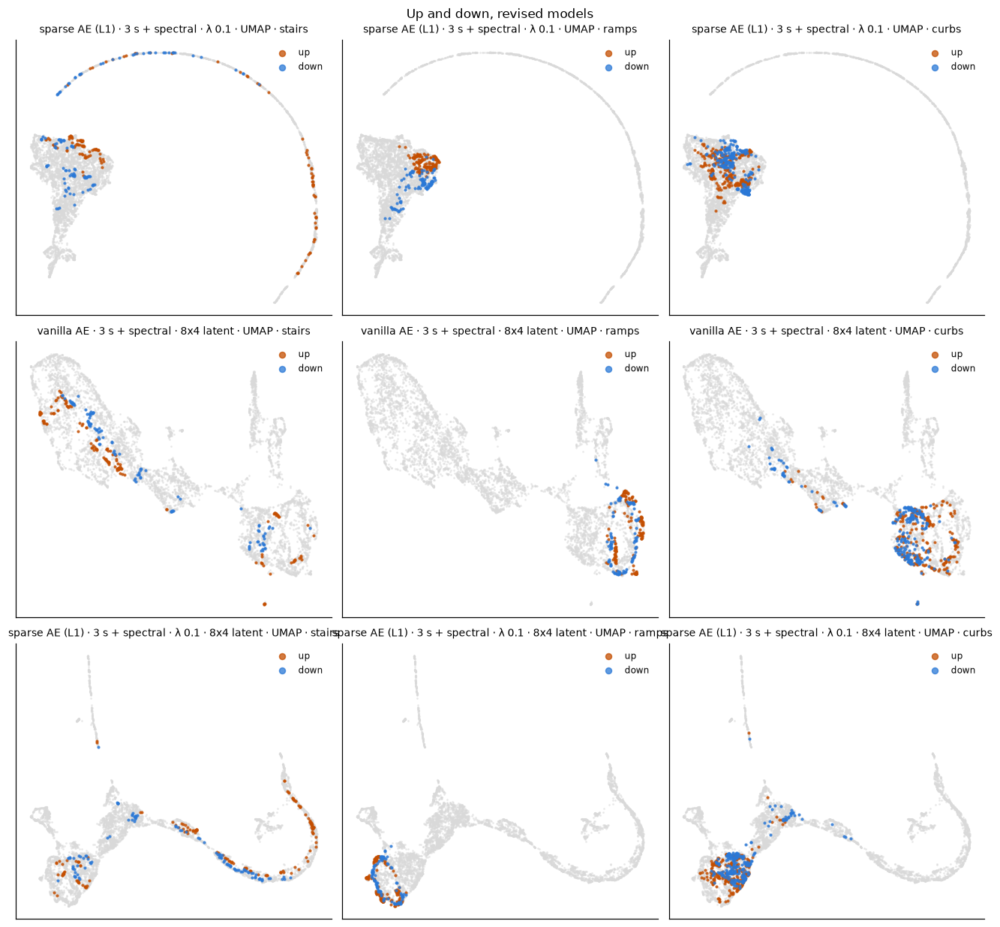

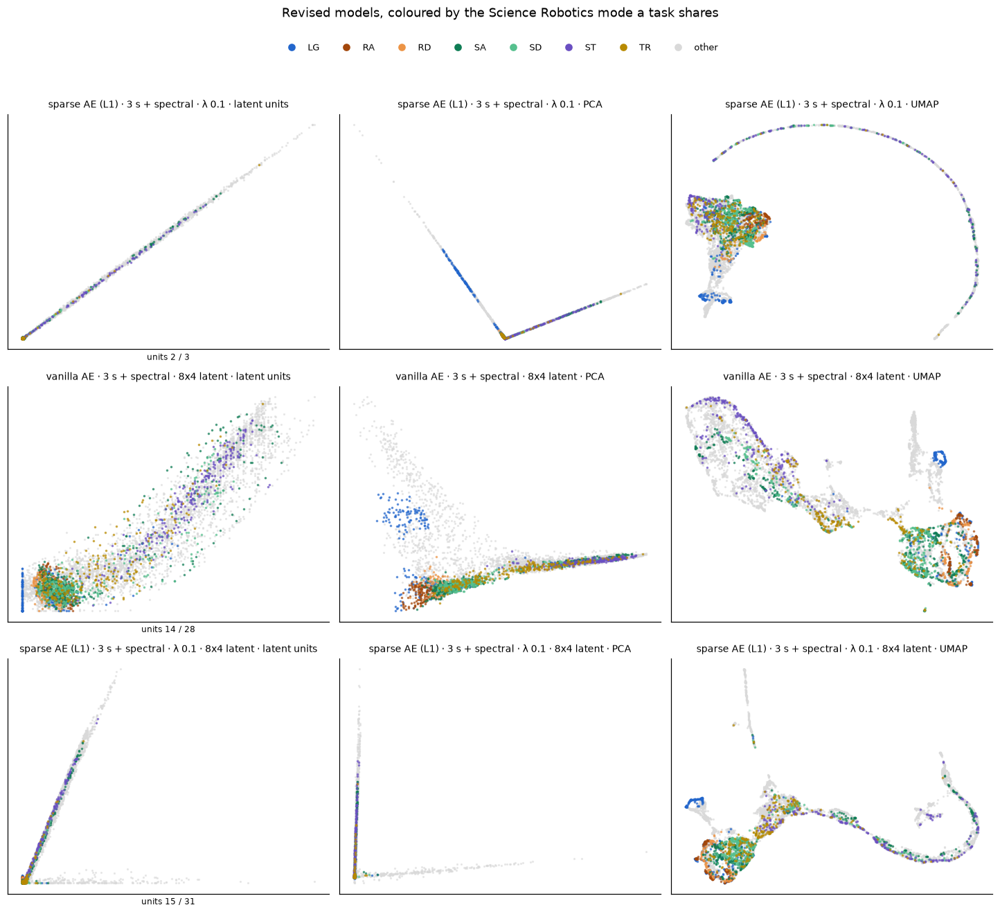

In [20]:
lv.plot_lens_grid(rev_views, labels, 'family', lv.FAMILY_C, 'Revised models, coloured by task family')
for name in REVISED:
    lv.plot_task_panels(views[name][('UMAP', 2)], labels, nt.TASK_FAMILIES, STYLES, f'{name}: UMAP 2-D, tasks by family')
lv.plot_lens_grid(rev_views, labels, 'controller_class', lv.CLASS_C, 'Revised models, coloured by controller class')
lv.plot_lens_grid(rev_views, labels, 'direction', lv.DIRECTION_C, 'Revised models, coloured by direction')
plot_direction_pairs(rev_views, 'Up and down, revised models')
lv.plot_lens_grid(rev_views, labels, 'scirob_mode', lv.SCIROB_C, 'Revised models, coloured by the Science Robotics mode a task shares')

### 5.4 Interactive 3-D, revised models
As in 3.6 and 4.4, on the same windows; standalone copies are in the interactive folder beside this notebook.

In [21]:
for name in REVISED:
    show_3d(name)

Standalone interactive copy: notebooks/nature/model_exploration/onboard/interactive/sparse_ae_l1_3_s_spectral_lambda_0_1_3d.html


Standalone interactive copy: notebooks/nature/model_exploration/onboard/interactive/vanilla_ae_3_s_spectral_8x4_latent_3d.html


Standalone interactive copy: notebooks/nature/model_exploration/onboard/interactive/sparse_ae_l1_3_s_spectral_lambda_0_1_8x4_latent_3d.html


### 5.5 What changed

- **λ sets how many blocks form, not whether they form.** At λ 0.1 the 4 x 8 latent splits into two blocks of
  identical units, one for the slow, posture-driven tasks (squats, lifting, sit-to-stand, tug of war, ball toss) and
  one for running and jumping (5.1); its UMAP is one arc and one cluster. At λ 0.3 more and smaller blocks survive,
  which is where its novelty units come from.
- **Reshaping helps the vanilla model more than the sparse one.** With 8 filters x 4 steps even the vanilla AE's units
  group by task family (5.1), but its variance concentrates too (1.8 directions) and reconstruction suffers.
- **The duplication is structural.** Units are filters read at successive time steps, and for slow or static movement
  those steps hold the same value. The penalty is per unit, so units that duplicate each other pay nothing extra.
  Removing the duplication needs a penalty on correlation between latent units, or a latent pooled over time.

## 6. What this shows

**For the awareness pipeline**

- **Use 3 s raw + spectral inputs for the latent.** They gave the cleaner geometry in both models: walking in one
  place, unseen movement types apart from it and from each other, and a sparse code that holds on new people. This
  matches what the boosted trees and the feature embeddings found (notebooks 02, 03).
- **Score two novelty signals next.** LOF on the latent (the ankle paper's score), and, for the sparse model, how
  strongly its novelty units fire, which needs no density estimate and says which kind of unfamiliar movement it is.
- **To de-duplicate the sparse latent, penalize correlation between latent units or pool each filter over time.**
  Lowering λ does not do it (section 5).
- **Keep the vanilla model as the baseline.** Its latent separates families too, but almost none of its units
  respond mainly to unseen movement.
- **The latent still mixes movement type with phase on 1 s windows.** If 1 s inputs are kept for latency, pooling
  each filter over its time steps would give a phase-free summary.

**Limits**

- Visual only: no separation or cluster scores yet. One seed per model is drawn; the novelty-unit counts and summary
  metrics cover all three, the layouts do not.
- Four test participants, 250 windows per task, restricted to windows with 3 s of clean history so all models are
  drawn on the same windows. UMAP and PCA are fitted on this sample, without labels.
- All models trained on the ID-safe tasks only, so the maps show where unseen movement lands.
- λ (0.3) was calibrated on 1 s inputs and kept for 3 s so that only the inputs differ; on 3 s inputs a stronger λ
  would also have stayed within 30% of vanilla. The 3 s windows add 2 s of latency, which a controller would have to
  accept or work around.